In [1]:

print("Information Retrieval - CLA 2")
print("Project: Text Classification Battle")
print("Dataset: SMS Spam Collection")
print("Algorithms: Decision Tree, KNN, SVM, Naive Bayes")
print("Setup completed successfully!")


Information Retrieval - CLA 2
Project: Text Classification Battle
Dataset: SMS Spam Collection
Algorithms: Decision Tree, KNN, SVM, Naive Bayes
Setup completed successfully!


In [2]:

import pandas as pd
from urllib.request import urlretrieve
from zipfile import ZipFile

# Download the SMS Spam Collection dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urlretrieve(url, "/content/sms_spam_collection.zip")

# Extract the downloaded file
with ZipFile("/content/sms_spam_collection.zip", "r") as zip_file:
    print("Files in dataset:", zip_file.namelist())
    zip_file.extractall("/content/sms_dataset")

# Load the messages
file_path = "/content/sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Remove duplicate records
df = df.drop_duplicates(subset=["label", "message"])

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 messages:")
print(df.head())


Files in dataset: ['SMSSpamCollection', 'readme']

Dataset loaded successfully!
Dataset shape: (5169, 2)

First 5 messages:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Class Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

Class Percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


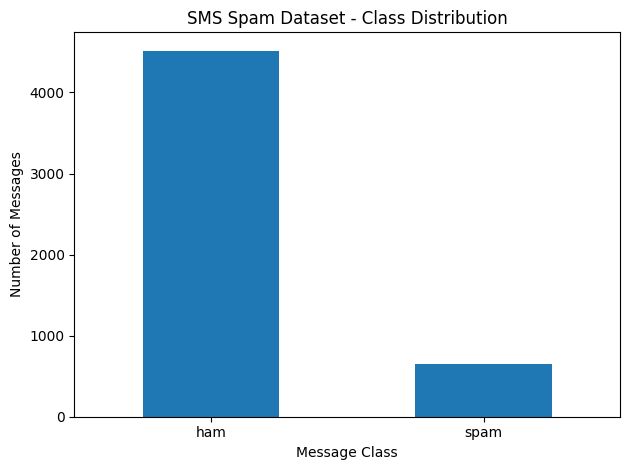

In [3]:

import matplotlib.pyplot as plt

# Count the messages in each class
class_counts = df["label"].value_counts()

print("Class Distribution:")
print(class_counts)

print("\nClass Percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Plot the distribution
class_counts.plot(kind="bar", rot=0)

plt.title("SMS Spam Dataset - Class Distribution")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


In [4]:

from sklearn.model_selection import train_test_split

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total messages:", len(df))
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())



Total messages: 5169
Training messages: 4135
Testing messages: 1034

Training class distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing class distribution:
label
ham     903
spam    131
Name: count, dtype: int64


In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("\nFirst 20 feature names:")
print(tfidf.get_feature_names_out()[:20])


Training TF-IDF shape: (4135, 10000)
Testing TF-IDF shape: (1034, 10000)

First 20 feature names:
['00' '00 sub' '00 subs' '000' '000 bonus' '000 cash' '000 homeowners'
 '000 pounds' '000 price' '000 prize' '000 xmas' '000pes' '000pes 48'
 '008704050406' '008704050406 sp' '0089' '02' '02 06' '02 09' '0207']


In [6]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import time

# Four required algorithms
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=30,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB()
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    # Measure training time
    start_time = time.perf_counter()
    model.fit(X_train_tfidf, y_train)
    training_time = time.perf_counter() - start_time

    # Measure prediction time
    start_time = time.perf_counter()
    y_pred = model.predict(X_test_tfidf)
    prediction_time = time.perf_counter() - start_time

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred,
            pos_label="spam",
            zero_division=0
        ),
        "Training Time (sec)": training_time,
        "Prediction Time (sec)": prediction_time
    })

    print(f"\n{name} completed successfully!")

results_df = pd.DataFrame(results).set_index("Algorithm")

print("\n===== COMPARATIVE RESULTS =====")
print(results_df.round(4).to_string())



Decision Tree completed successfully!

KNN completed successfully!

SVM completed successfully!

Naive Bayes completed successfully!

===== COMPARATIVE RESULTS =====
               Accuracy  Precision  Recall  F1-Score  Training Time (sec)  Prediction Time (sec)
Algorithm                                                                                       
Decision Tree    0.9623     0.9035  0.7863    0.8408               0.4253                 0.0011
KNN              0.9594     0.9785  0.6947    0.8125               0.0069                 0.1479
SVM              0.9787     0.9580  0.8702    0.9120               0.0245                 0.0006
Naive Bayes      0.9652     1.0000  0.7252    0.8407               0.0153                 0.0008


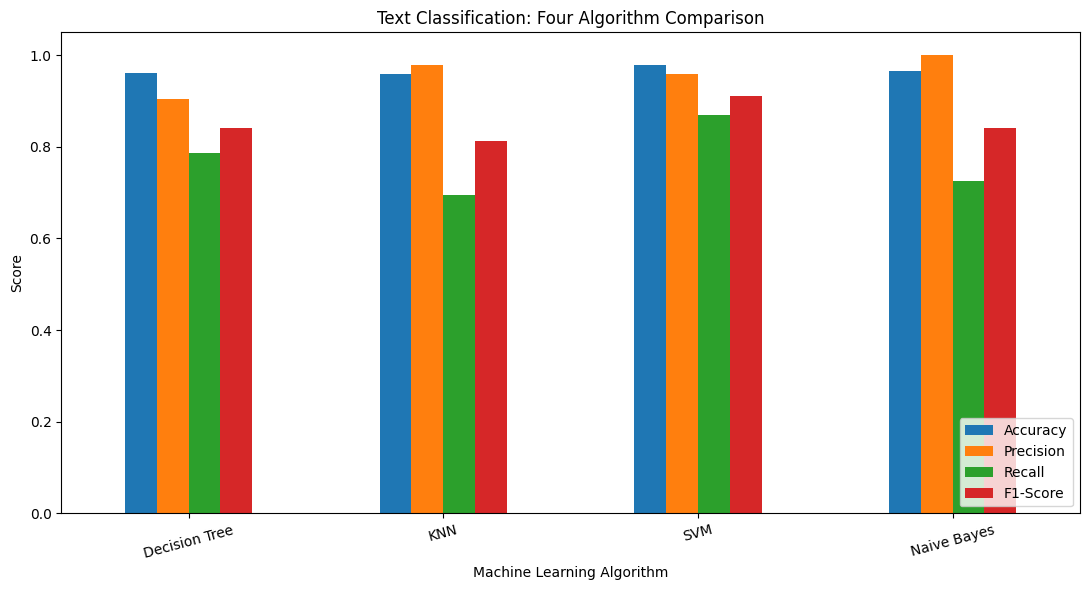

In [7]:

# Compare the four evaluation metrics
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df[metric_columns].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05)
)

plt.title("Text Classification: Four Algorithm Comparison")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("algorithm_comparison.png", dpi=300)
plt.show()


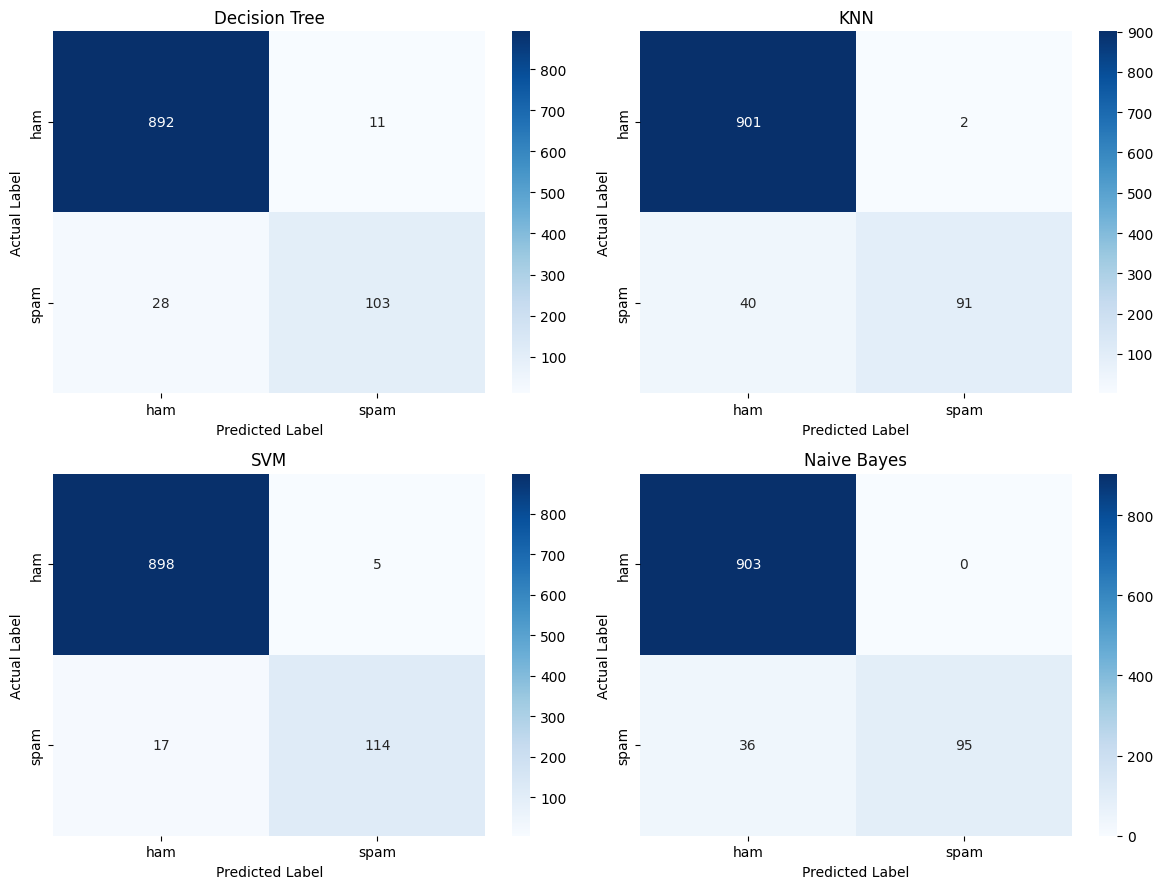

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("four_confusion_matrices.png", dpi=300)
plt.show()


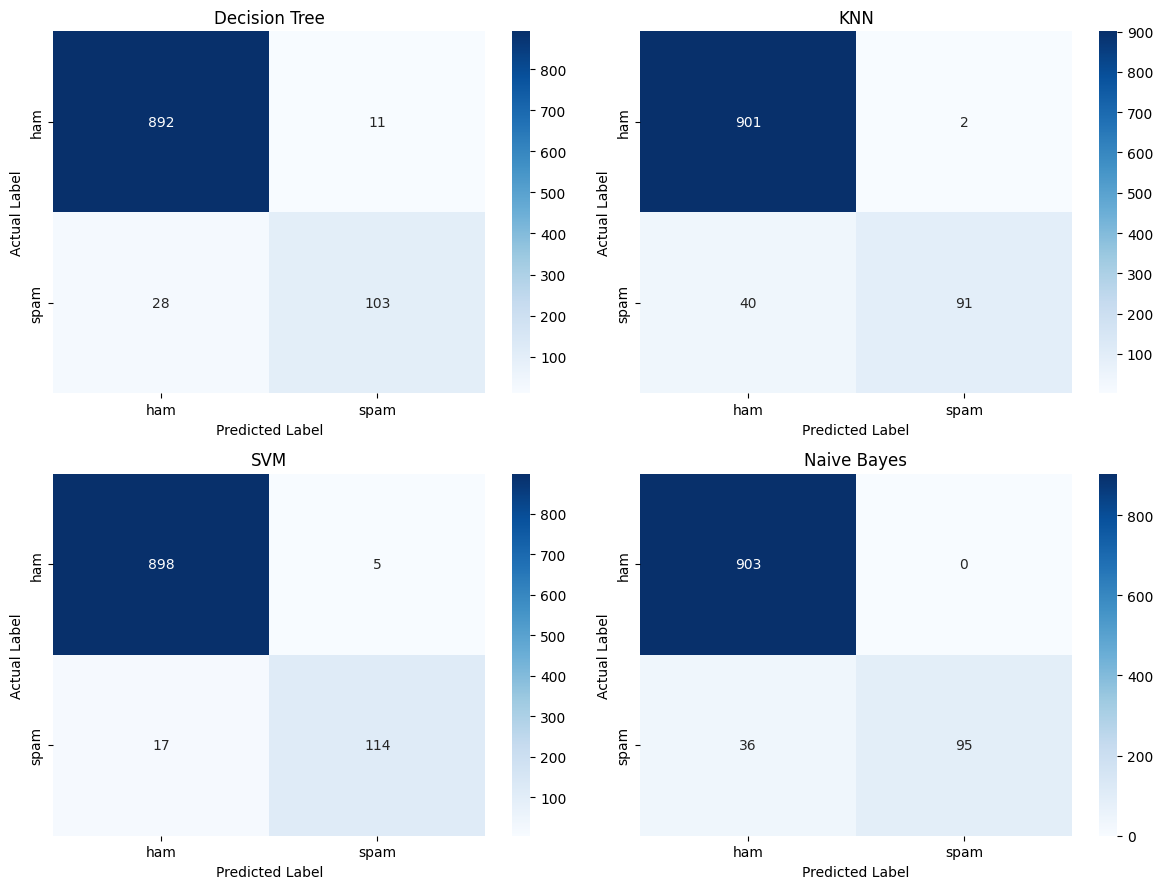

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("four_confusion_matrices.png", dpi=300)
plt.show()


In [10]:

results_df.to_csv("algorithm_comparison.csv")

print("Results saved as algorithm_comparison.csv")
print("\nBest model by spam F1-score:")
print(results_df["F1-Score"].idxmax())


Results saved as algorithm_comparison.csv

Best model by spam F1-score:
SVM


KNN WHAT-IF EXPERIMENT
 K  Accuracy  Precision  Recall  F1-Score
 1    0.9652     0.9439  0.7710    0.8487
 3    0.9632     0.9794  0.7252    0.8333
 5    0.9594     0.9785  0.6947    0.8125
 7    0.9555     1.0000  0.6489    0.7870
11    0.9565     1.0000  0.6565    0.7926


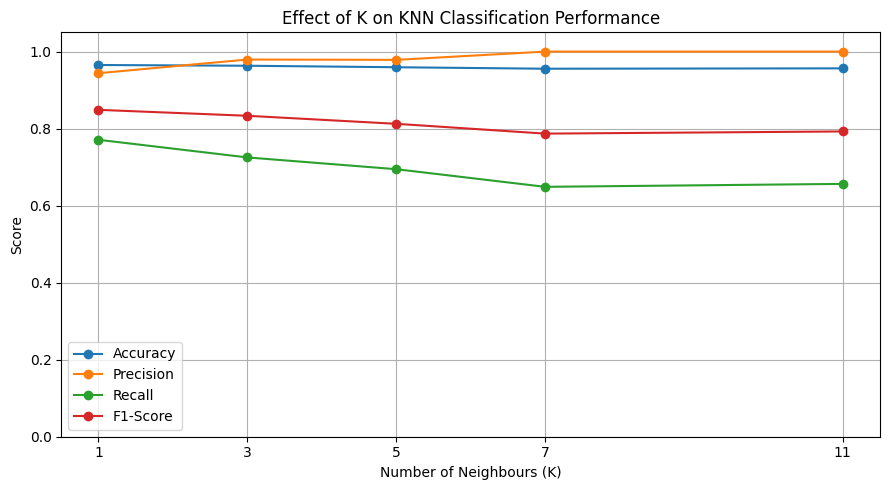

In [11]:

# What-if experiment: Change K in KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

k_values = [1, 3, 5, 7, 11]
knn_results = []

for k in k_values:
    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute"
    )

    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, pos_label="spam", zero_division=0
        )
    })

knn_results_df = pd.DataFrame(knn_results)

print("KNN WHAT-IF EXPERIMENT")
print(knn_results_df.round(4).to_string(index=False))

knn_results_df.set_index("K").plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Effect of K on KNN Classification Performance")
plt.xlabel("Number of Neighbours (K)")
plt.ylabel("Score")
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True)
plt.tight_layout()
plt.savefig("knn_what_if_analysis.png", dpi=300)
plt.show()

knn_results_df.to_csv("knn_what_if_results.csv", index=False)


In [12]:

from google.colab import files

files.download("algorithm_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

files.download("knn_what_if_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

from google.colab import files

files.download("algorithm_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

files.download("four_confusion_matrices.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

files.download("knn_what_if_analysis.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>